# Import Libraries & Dataset

In [7]:
!pip install -q tfds-nightly tensorflow matplotlib importlib_resources

In [3]:
import pandas as pd
from PIL import Image
import os
import xml.etree.ElementTree as ET
import random
import matplotlib.pyplot as plt
import seaborn as sns
import cv2
import numpy as np
import tensorflow as tf
import tensorflow_datasets as tfds


In [4]:
tfds.list_builders()

['abstract_reasoning',
 'accentdb',
 'aeslc',
 'aflw2k3d',
 'ag_news_subset',
 'ai2_arc',
 'ai2_arc_with_ir',
 'ai2dcaption',
 'aloha_mobile',
 'amazon_us_reviews',
 'anli',
 'answer_equivalence',
 'arc',
 'asimov_dilemmas_auto_val',
 'asimov_dilemmas_scifi_train',
 'asimov_dilemmas_scifi_val',
 'asimov_injury_val',
 'asimov_multimodal_auto_val',
 'asimov_multimodal_manual_val',
 'asimov_v2_constraints_with_rationale',
 'asimov_v2_constraints_without_rationale',
 'asimov_v2_injuries',
 'asimov_v2_videos',
 'asqa',
 'asset',
 'assin2',
 'asu_table_top_converted_externally_to_rlds',
 'austin_buds_dataset_converted_externally_to_rlds',
 'austin_sailor_dataset_converted_externally_to_rlds',
 'austin_sirius_dataset_converted_externally_to_rlds',
 'bair_robot_pushing_small',
 'bc_z',
 'bccd',
 'beans',
 'bee_dataset',
 'beir',
 'berkeley_autolab_ur5',
 'berkeley_cable_routing',
 'berkeley_fanuc_manipulation',
 'berkeley_gnm_cory_hall',
 'berkeley_gnm_recon',
 'berkeley_gnm_sac_son',
 'berkel

In [9]:
# Load the PASCAL VOC 2012 dataset from TensorFlow Datasets
voc_ds, info = tfds.load('voc/2012', with_info=True, shuffle_files=True)

# Display dataset information
print(info)

Dl Completed...: 0 url [00:00, ? url/s]

Dl Size...: 0 MiB [00:00, ? MiB/s]

Extraction completed...: 0 file [00:00, ? file/s]

Generating splits...:   0%|          | 0/3 [00:00<?, ? splits/s]

Generating test examples...: 0 examples [00:00, ? examples/s]

Shuffling /root/tensorflow_datasets/voc/2012/incomplete.1UCDRD_5.0.0/voc-test.tfrecord-[0-9][0-9][0-9][0-9][0-…

Generating train examples...: 0 examples [00:00, ? examples/s]

Shuffling /root/tensorflow_datasets/voc/2012/incomplete.1UCDRD_5.0.0/voc-train.tfrecord-[0-9][0-9][0-9][0-9][0…

Generating validation examples...: 0 examples [00:00, ? examples/s]

Shuffling /root/tensorflow_datasets/voc/2012/incomplete.1UCDRD_5.0.0/voc-validation.tfrecord-[0-9][0-9][0-9][0…

Dataset voc downloaded and prepared to /root/tensorflow_datasets/voc/2012/5.0.0. Subsequent calls will reuse this data.
tfds.core.DatasetInfo(
    name='voc',
    full_name='voc/2012/5.0.0',
    description="""
    This dataset contains the data from the PASCAL Visual Object Classes Challenge,
    corresponding to the Classification and Detection competitions.
    
    In the Classification competition, the goal is to predict the set of labels
    contained in the image, while in the Detection competition the goal is to
    predict the bounding box and label of each individual object.
    annotations.
    """,
    config_description="""
    This dataset contains the data from the PASCAL Visual Object Classes Challenge
    2012, a.k.a. VOC2012.
    
    A total of 11540 images are included in this dataset, where each image
    contains a set of objects, out of 20 different classes, making a total of
    27450 annotated objects.
    
    """,
    homepage='http://host.robots.ox.ac.uk/pas

# EDA

## Dataset Overview

In [11]:
train_dataset = voc_ds['train']
for example in train_dataset.take(1):
    image = example['image']
    label = example['objects']['label']

Does every image has a corresponding annotation?

In [18]:
# Verify that every image entry in TFDS has objects/annotations associated with it
total_examples = 0
valid_examples = 0

for split in ['train', 'validation']:
    if split in voc_ds:
        for example in voc_ds[split]:
            total_examples += 1
            if 'image' in example and 'objects' in example:
                valid_examples += 1

print(f"Total items processed: {total_examples}")
print(f"Items with corresponding annotations: {valid_examples}")
print(f"Mismatch or missing annotations: {total_examples - valid_examples}")

Total items processed: 11540
Items with corresponding annotations: 11540
Mismatch or missing annotations: 0


In [20]:
# Extract some filenames from the tfds dataset instead
tfds_sample_filenames = []
for example in voc_ds['train'].take(5):
    filename = example['image/filename'].numpy().decode('utf-8')
    tfds_sample_filenames.append(filename)

print("Sample filenames from TFDS:", tfds_sample_filenames)
print(type(tfds_sample_filenames))

Sample filenames from TFDS: ['2009_004764.jpg', '2009_004319.jpg', '2009_002750.jpg', '2008_007691.jpg', '2011_000277.jpg']
<class 'list'>


## Image Dimensions Analysis

In [21]:
image_data = []

# We will extract metadata from all splits in our TFDS dataset to reconstruct image_df
for split in ['train', 'validation', 'test']:
    if split in voc_ds:
        for example in voc_ds[split]:
            # Decode tensorflow tensor values
            filename = example['image/filename'].numpy().decode('utf-8')
            img_shape = example['image'].shape
            height, width, channels = img_shape[0], img_shape[1], img_shape[2]

            image_data.append({
                'filename': filename,
                'width': width,
                'height': height,
                'format': 'JPEG', # PASCAL VOC uses JPEG images
                'mode': 'RGB' if channels == 3 else 'L',
                'aspect_ratio': width / height
            })

image_df = pd.DataFrame(image_data)
display(image_df.head())

,filename,width,height,format,mode,aspect_ratio
0,2009_004764.jpg,500,360,JPEG,RGB,1.388889
1,2009_004319.jpg,500,334,JPEG,RGB,1.497006
2,2009_002750.jpg,500,333,JPEG,RGB,1.501502
3,2008_007691.jpg,375,500,JPEG,RGB,0.750000
4,2011_000277.jpg,500,375,JPEG,RGB,1.333333


Statistical summary

In [22]:
image_df.describe().T

,count,mean,std,min,25%,50%,75%,max
width,22531.0,470.564777,59.040499,142.000,500.000000,500.000000,500.00000,500.000000
height,22531.0,385.884648,63.740797,71.000,335.000000,375.000000,377.00000,500.000000
aspect_ratio,22531.0,1.266955,0.306172,0.284,1.312336,1.333333,1.47929,7.042254


Visualize image dimensions

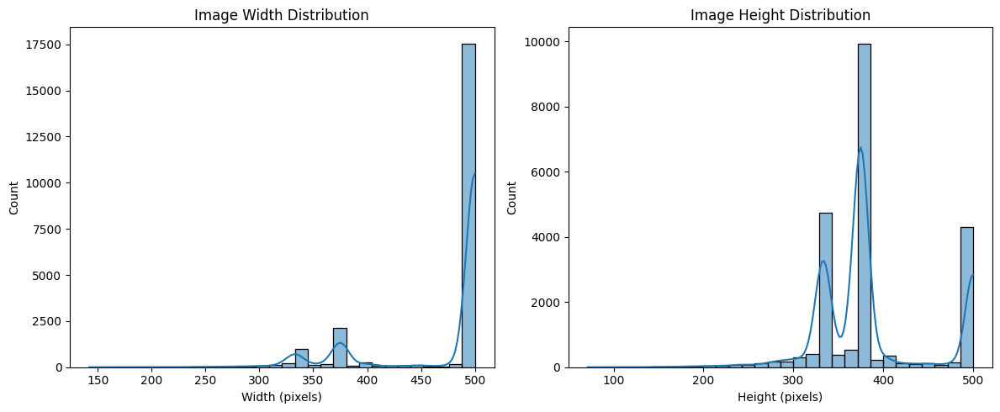

In [23]:
plt.figure(figsize=(12, 5))

plt.subplot(1, 2, 1)
sns.histplot(image_df['width'], bins=30, kde=True)
plt.title("Image Width Distribution")
plt.xlabel("Width (pixels)")

plt.subplot(1, 2, 2)
sns.histplot(image_df['height'], bins=30, kde=True)
plt.title("Image Height Distribution")
plt.xlabel("Height (pixels)")

plt.tight_layout()
plt.show()

Width vs. height

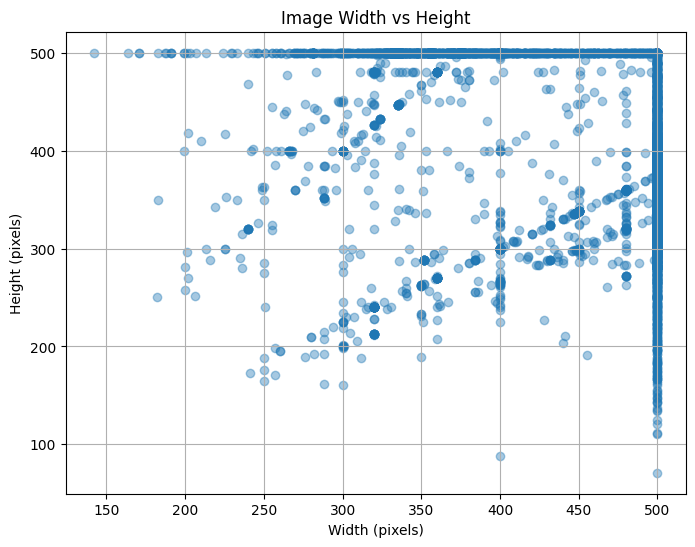

In [24]:
plt.figure(figsize=(8, 6))

plt.scatter(image_df['width'], image_df['height'], alpha=0.4)

plt.xlabel("Width (pixels)")
plt.ylabel("Height (pixels)")
plt.title("Image Width vs Height")

plt.grid()
plt.show()

Image formats and color channels

In [25]:
print("Image Formats:")
print(image_df['format'].value_counts())

print("\nImage Modes:")
print(image_df['mode'].value_counts())

Image Formats:
format
JPEG    22531
Name: count, dtype: int64

Image Modes:
mode
RGB    22531
Name: count, dtype: int64


random image samples

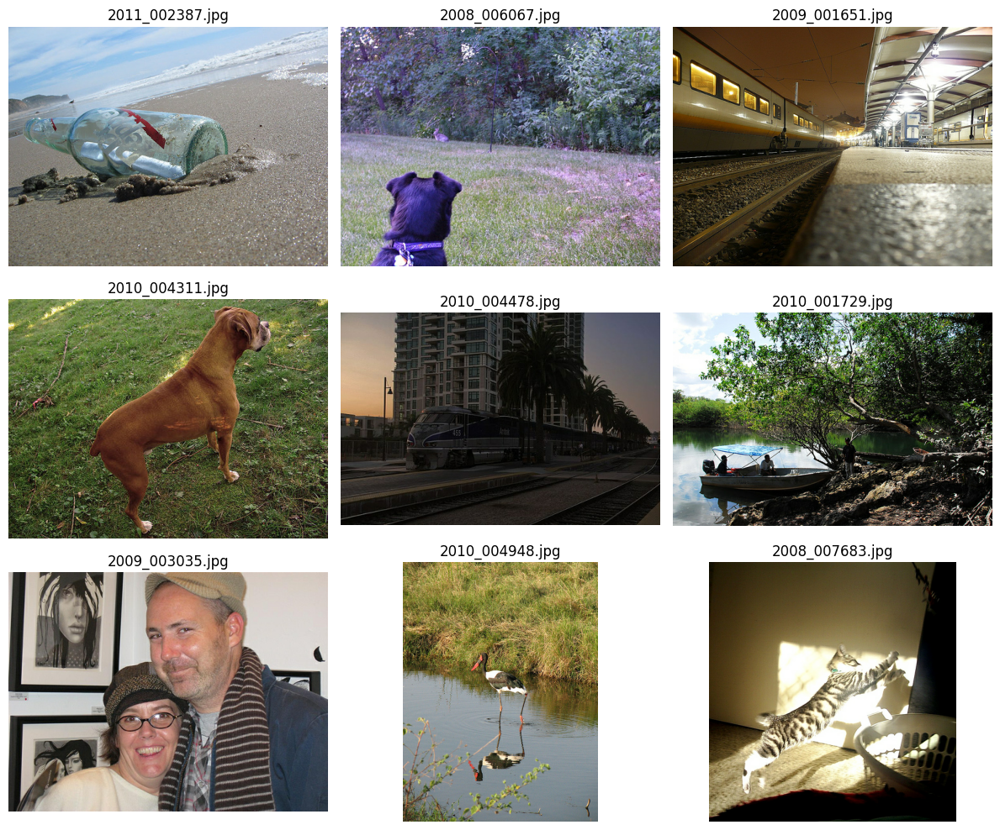

In [27]:
# Retrieve and sample directly from the TFDS dataset
train_examples = list(voc_ds['train'].take(50)) # Take a small batch to sample from
sample_examples = random.sample(train_examples, min(len(train_examples), 9))

plt.figure(figsize=(12, 10))

for i, example in enumerate(sample_examples):
    img = example['image'].numpy()
    filename = example['image/filename'].numpy().decode('utf-8')

    plt.subplot(3, 3, i + 1)
    plt.imshow(img)
    plt.title(filename)
    plt.axis('off')

plt.tight_layout()
plt.show()

## Analyze XML annotations

In [29]:
annotation_data = []

# Map from integer label index to PASCAL VOC class name
# tfds metadata contains the labels list
class_names = info.features['objects']['label'].names

for split in ['train', 'validation']:
    if split in voc_ds:
        for example in voc_ds[split]:
            filename = example['image/filename'].numpy().decode('utf-8')
            img_shape = example['image'].shape
            height, width = img_shape[0], img_shape[1]

            objects = example['objects']
            # Bounding boxes are normalized [ymin, xmin, ymax, xmax] in tfds
            bboxes = objects['bbox'].numpy()
            labels = objects['label'].numpy()

            # Some configurations might have difficult / truncated flags in tfds
            difficults = objects.get('is_difficult', tf.zeros_like(labels)).numpy()
            truncateds = objects.get('is_truncated', tf.zeros_like(labels)).numpy()

            for idx in range(len(labels)):
                ymin, xmin, ymax, xmax = bboxes[idx]

                # Convert normalized coordinates back to pixel coordinates
                abs_xmin = xmin * width
                abs_ymin = ymin * height
                abs_xmax = xmax * width
                abs_ymax = ymax * height

                class_name = class_names[labels[idx]]

                annotation_data.append({
                    'filename': filename,
                    'class': class_name,
                    'difficult': int(difficults[idx]),
                    'truncated': int(truncateds[idx]),
                    'image_width': width,
                    'image_height': height,
                    'xmin': abs_xmin,
                    'ymin': abs_ymin,
                    'xmax': abs_xmax,
                    'ymax': abs_ymax,
                    'bbox_width': abs_xmax - abs_xmin,
                    'bbox_height': abs_ymax - abs_ymin,
                    'bbox_area': (abs_xmax - abs_xmin) * (abs_ymax - abs_ymin)
                })

annotation_df = pd.DataFrame(annotation_data)

annotation_df['bbox_area_ratio'] = (
    annotation_df['bbox_area'] /
    (annotation_df['image_width'] * annotation_df['image_height'])
)

display(annotation_df.head())

,filename,class,difficult,truncated,image_width,image_height,xmin,ymin,xmax,ymax,bbox_width,bbox_height,bbox_area,bbox_area_ratio
0,2008_004781.jpg,person,0,1,500,333,51.0,65.0,276.0,333.000000,225.0,268.000000,60300.00000,0.362162
1,2008_004781.jpg,tvmonitor,0,1,500,333,215.0,96.0,500.0,333.000000,285.0,237.000000,67545.00000,0.405676
2,2011_002053.jpg,train,0,1,500,375,1.0,113.0,486.0,342.000000,485.0,229.000000,111065.00000,0.592347
3,2011_002053.jpg,train,1,1,500,375,1.0,86.0,335.0,127.000008,334.0,41.000008,13694.00293,0.073035
4,2011_003162.jpg,pottedplant,0,1,500,373,330.0,1.0,500.0,340.000000,170.0,339.000000,57630.00000,0.309008


### Object class distribution

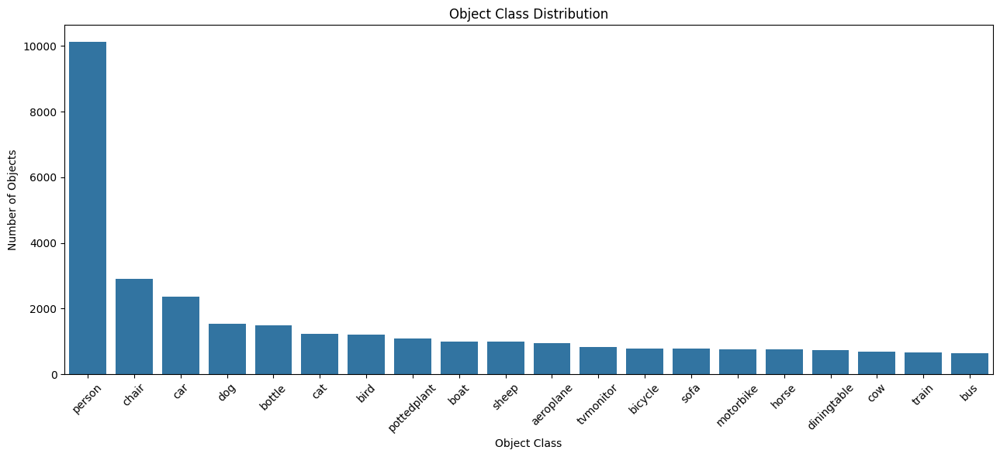

class
person         10129
chair           2906
car             2364
dog             1541
bottle          1482
cat             1227
bird            1221
pottedplant     1099
boat             999
sheep            994
aeroplane        954
tvmonitor        826
bicycle          790
sofa             786
motorbike        751
horse            750
diningtable      747
cow              702
train            656
bus              637
Name: count, dtype: int64


In [30]:
class_counts = annotation_df['class'].value_counts()

plt.figure(figsize=(13, 6))

sns.barplot(
    x=class_counts.index,
    y=class_counts.values
)

plt.title("Object Class Distribution")
plt.xlabel("Object Class")
plt.ylabel("Number of Objects")
plt.xticks(rotation=45)

plt.tight_layout()
plt.show()

print(class_counts)

Number of objects per image

In [31]:
objects_per_image = annotation_df.groupby('filename').size()

print("Average objects per annotated image:",
      objects_per_image.mean())

print("Maximum objects in one image:",
      objects_per_image.max())

print("Minimum objects in one annotated image:",
      objects_per_image.min())

Average objects per annotated image: 2.7349220103986136
Maximum objects in one image: 56
Minimum objects in one annotated image: 1


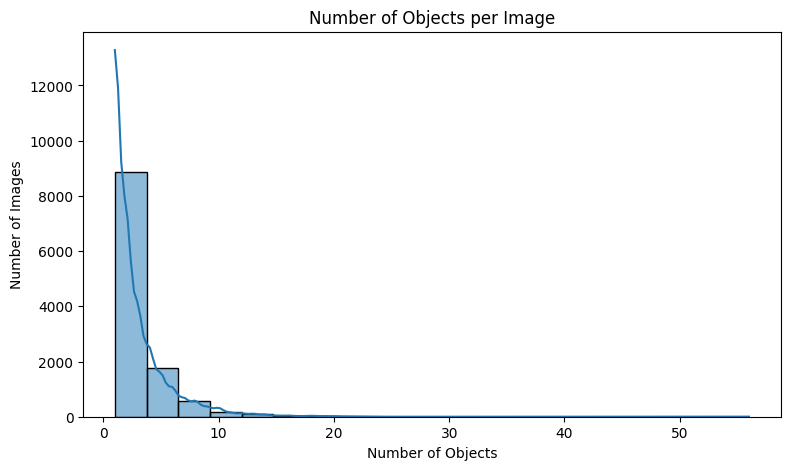

In [32]:
plt.figure(figsize=(9, 5))

sns.histplot(objects_per_image, bins=20, kde=True)

plt.title("Number of Objects per Image")
plt.xlabel("Number of Objects")
plt.ylabel("Number of Images")

plt.show()

### Bounding box analysis

In [33]:
annotation_df['bbox_width_ratio'] = (
    annotation_df['bbox_width'] / annotation_df['image_width']
)

annotation_df['bbox_height_ratio'] = (
    annotation_df['bbox_height'] / annotation_df['image_height']
)

annotation_df['bbox_area_ratio'] = (
    annotation_df['bbox_area'] /
    (annotation_df['image_width'] * annotation_df['image_height'])
)

display(
    annotation_df[
        ['bbox_width', 'bbox_height', 'bbox_area',
         'bbox_width_ratio', 'bbox_height_ratio',
         'bbox_area_ratio']
    ].describe().T
)

,count,mean,std,min,25%,50%,75%,max
bbox_width,31561.0,160.208389,136.136063,2.000008,51.000000,114.000000,240.000000,499.000000
bbox_height,31561.0,162.269104,115.397606,3.999992,63.000000,138.000000,243.000000,499.000000
bbox_area,31561.0,36411.660156,45188.273438,14.000053,3305.999023,16058.000000,54060.000000,249001.000000
bbox_width_ratio,31561.0,0.341651,0.288829,0.004167,0.106000,0.242000,0.518000,0.998000
bbox_height_ratio,31561.0,0.422717,0.285765,0.008000,0.170000,0.368750,0.647208,0.998000
bbox_area_ratio,31561.0,0.202709,0.248271,0.000081,0.018512,0.089789,0.302544,0.996004


Bounding box dimensions distribution

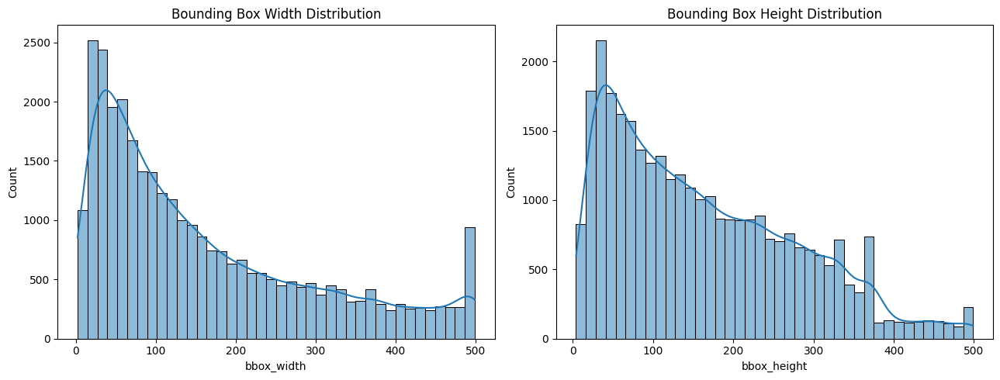

In [34]:
plt.figure(figsize=(13, 5))

plt.subplot(1, 2, 1)
sns.histplot(annotation_df['bbox_width'], bins=40, kde=True)
plt.title("Bounding Box Width Distribution")

plt.subplot(1, 2, 2)
sns.histplot(annotation_df['bbox_height'], bins=40, kde=True)
plt.title("Bounding Box Height Distribution")

plt.tight_layout()
plt.show()

Object relative area

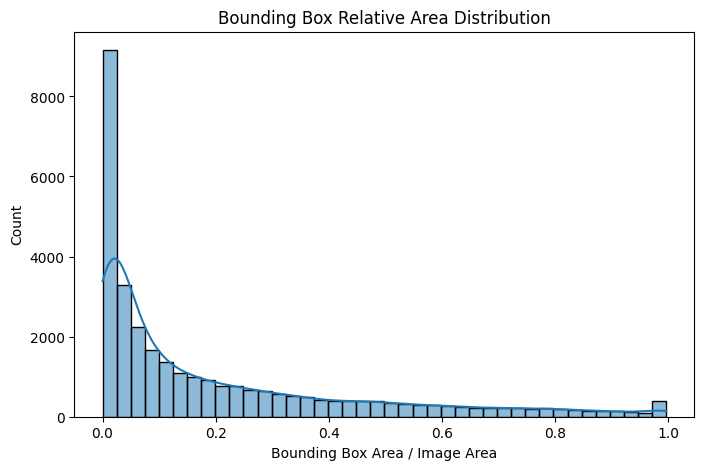

In [35]:
plt.figure(figsize=(8, 5))

sns.histplot(annotation_df['bbox_area_ratio'], bins=40, kde=True)

plt.title("Bounding Box Relative Area Distribution")
plt.xlabel("Bounding Box Area / Image Area")

plt.show()

Annotation quality

In [36]:
invalid_boxes = annotation_df[
    (annotation_df['xmin'] >= annotation_df['xmax']) |
    (annotation_df['ymin'] >= annotation_df['ymax']) |
    (annotation_df['xmin'] < 0) |
    (annotation_df['ymin'] < 0) |
    (annotation_df['xmax'] > annotation_df['image_width']) |
    (annotation_df['ymax'] > annotation_df['image_height'])
]

print("Total bounding boxes:", len(annotation_df))
print("Invalid bounding boxes:", len(invalid_boxes))

Total bounding boxes: 31561
Invalid bounding boxes: 0


In [38]:
# Since we are using TFDS, we can verify if there are any images with zero annotated objects
# by checking our structured annotation_df or counting directly from the dataset splits.
empty_annotations = []

for split in ['train', 'validation']:
    if split in voc_ds:
        for example in voc_ds[split]:
            filename = example['image/filename'].numpy().decode('utf-8')
            num_objects = len(example['objects']['label'].numpy())
            if num_objects == 0:
                empty_annotations.append(filename)

print("Images with zero objects:", len(empty_annotations))

Images with zero objects: 0


## Visualize bounding boxes on sample images

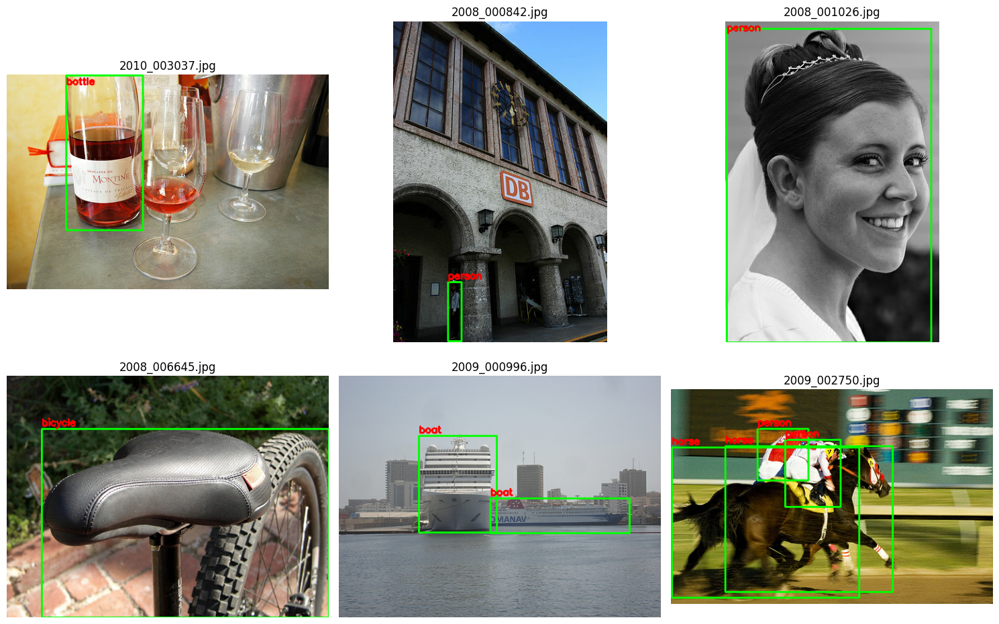

In [40]:
# Retrieve and sample directly from the TFDS dataset
train_examples = list(voc_ds['train'].take(50))
sample_examples = random.sample(train_examples, min(len(train_examples), 6))

plt.figure(figsize=(15, 10))
class_names = info.features['objects']['label'].names

for i, example in enumerate(sample_examples):
    # Extract image and scale bounding boxes
    img = example['image'].numpy().copy()
    height, width, _ = img.shape
    filename = example['image/filename'].numpy().decode('utf-8')

    bboxes = example['objects']['bbox'].numpy()
    labels = example['objects']['label'].numpy()

    for idx, bbox in enumerate(bboxes):
        ymin, xmin, ymax, xmax = bbox

        # Convert normalized coordinates to pixel coordinates
        abs_xmin = int(xmin * width)
        abs_ymin = int(ymin * height)
        abs_xmax = int(xmax * width)
        abs_ymax = int(ymax * height)

        class_name = class_names[labels[idx]]

        # Draw bounding boxes and text labels on image
        cv2.rectangle(img, (abs_xmin, abs_ymin), (abs_xmax, abs_ymax), (0, 255, 0), 2)
        cv2.putText(img, class_name, (abs_xmin, max(abs_ymin - 5, 15)),
                    cv2.FONT_HERSHEY_SIMPLEX, 0.5, (255, 0, 0), 2)

    plt.subplot(2, 3, i + 1)
    plt.imshow(img)
    plt.title(filename)
    plt.axis('off')

plt.tight_layout()
plt.show()

# Dataset Summary

In [42]:
print("=" * 50)
print("PASCAL VOC 2012 - DATASET EDA SUMMARY")
print("=" * 50)

print(f"\nTotal Images: {len(image_df)}")
print(f"Total Unique Annotated Images: {annotation_df['filename'].nunique()}")
print(f"Total Annotated Objects: {len(annotation_df)}")

print("\nIMAGE DIMENSIONS")
print(f"Minimum Width: {image_df['width'].min()}")
print(f"Maximum Width: {image_df['width'].max()}")
print(f"Average Width: {image_df['width'].mean():.2f}")

print(f"Minimum Height: {image_df['height'].min()}")
print(f"Maximum Height: {image_df['height'].max()}")
print(f"Average Height: {image_df['height'].mean():.2f}")

print("\nOBJECT STATISTICS")
print(f"Number of Classes: {annotation_df['class'].nunique()}")
print(f"Average Objects per Image: {objects_per_image.mean():.2f}")
print(f"Maximum Objects per Image: {objects_per_image.max()}")

print("\nANNOTATION QUALITY")
print(f"Invalid Bounding Boxes: {len(invalid_boxes)}")
print(f"Images with No Objects: {len(empty_annotations)}")

print("\nCLASS DISTRIBUTION")
print(class_counts)

print("=" * 50)

PASCAL VOC 2012 - DATASET EDA SUMMARY

Total Images: 22531
Total Unique Annotated Images: 11540
Total Annotated Objects: 31561

IMAGE DIMENSIONS
Minimum Width: 142
Maximum Width: 500
Average Width: 470.56
Minimum Height: 71
Maximum Height: 500
Average Height: 385.88

OBJECT STATISTICS
Number of Classes: 20
Average Objects per Image: 2.73
Maximum Objects per Image: 56

ANNOTATION QUALITY
Invalid Bounding Boxes: 0
Images with No Objects: 0

CLASS DISTRIBUTION
class
person         10129
chair           2906
car             2364
dog             1541
bottle          1482
cat             1227
bird            1221
pottedplant     1099
boat             999
sheep            994
aeroplane        954
tvmonitor        826
bicycle          790
sofa             786
motorbike        751
horse            750
diningtable      747
cow              702
train            656
bus              637
Name: count, dtype: int64


# Preprocessing

## Data Quality Checks

### Missing values and duplicates

In [43]:
print(annotation_df.isnull().sum())
print("Duplicate rows:", annotation_df.duplicated().sum())

filename             0
class                0
difficult            0
truncated            0
image_width          0
image_height         0
xmin                 0
ymin                 0
xmax                 0
ymax                 0
bbox_width           0
bbox_height          0
bbox_area            0
bbox_area_ratio      0
bbox_width_ratio     0
bbox_height_ratio    0
dtype: int64
Duplicate rows: 0


### Missing values and duplicates

In [62]:
# Box area as a fraction of the image area
annotation_df['bbox_area_ratio'] = (
    annotation_df['bbox_area'] /
    (annotation_df['image_width'] * annotation_df['image_height'])
)

# 2. Invalid boxes: max <= min (flipped or zero-size)
invalid_boxes = annotation_df[
    (annotation_df['xmax'] <= annotation_df['xmin']) |
    (annotation_df['ymax'] <= annotation_df['ymin'])
]

# 3. Boxes outside the image (VOC coordinates start at 1)
out_of_bounds = annotation_df[
    (annotation_df['xmin'] < 1) | (annotation_df['ymin'] < 1) |
    (annotation_df['xmax'] > annotation_df['image_width']) |
    (annotation_df['ymax'] > annotation_df['image_height'])
]

# 4. Very tiny boxes (less than 0.1% of the image area)
tiny_boxes = annotation_df[annotation_df['bbox_area_ratio'] < 0.001]

print("Invalid boxes:", len(invalid_boxes))
print("Out of bounds boxes:", len(out_of_bounds))
print("Tiny boxes:", len(tiny_boxes))

Invalid boxes: 0
Out of bounds boxes: 142
Tiny boxes: 385


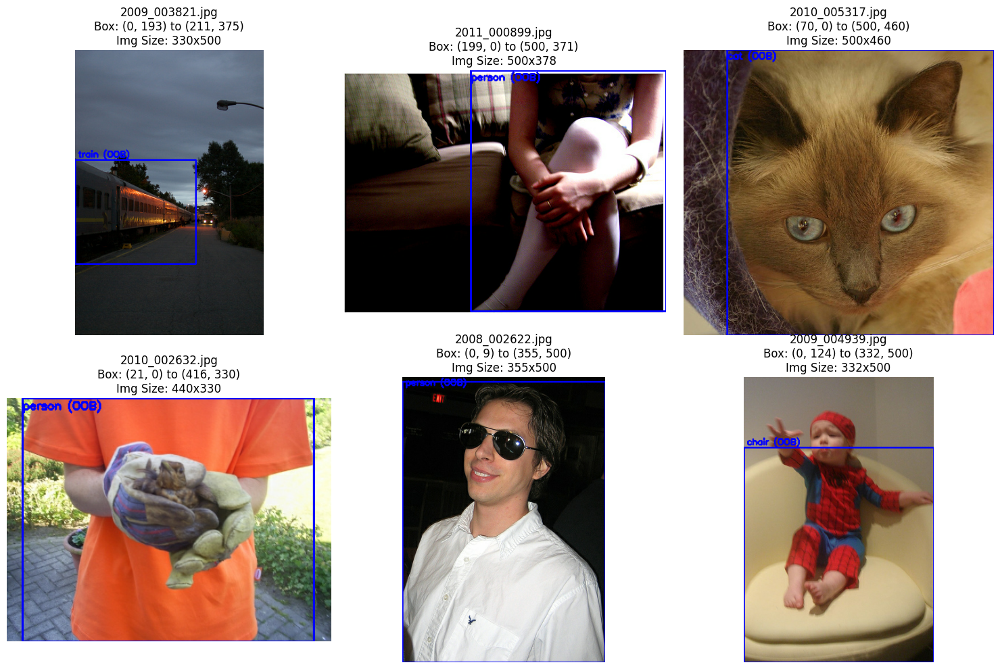

In [48]:
# Get a random sample of out-of-bounds annotations
num_samples = min(len(out_of_bounds), 6)
sampled_bounds = out_of_bounds.sample(num_samples, random_state=42)

# Create a dictionary of filename -> list of boxes for easy lookup
sample_filenames = set(sampled_bounds['filename'])

# Retrieve the raw images from our TFDS dataset splits
image_cache = {}
for split in ['train', 'validation']:
    if len(image_cache) >= len(sample_filenames):
        break
    for example in voc_ds[split]:
        filename = example['image/filename'].numpy().decode('utf-8')
        if filename in sample_filenames:
            image_cache[filename] = example['image'].numpy().copy()
        if len(image_cache) >= len(sample_filenames):
            break

# Plot the sampled images with their out-of-bounds bounding boxes
plt.figure(figsize=(15, 10))
for i, (idx, row) in enumerate(sampled_bounds.iterrows()):
    filename = row['filename']
    img = image_cache.get(filename)

    if img is not None:
        # Create a copy to draw on safely
        img_draw = img.copy()
        h, w, _ = img_draw.shape

        # Bounding box coordinates from the row
        xmin, ymin, xmax, ymax = int(row['xmin']), int(row['ymin']), int(row['xmax']), int(row['ymax'])

        # Draw the box boundaries clipping safely for visualization
        cv2.rectangle(img_draw, (xmin, ymin), (xmax, ymax), (0, 0, 255), 2)
        cv2.putText(img_draw, f"{row['class']} (OOB)", (max(xmin, 5), max(ymin - 5, 15)),
                    cv2.FONT_HERSHEY_SIMPLEX, 0.5, (0, 0, 255), 2)

        plt.subplot(2, 3, i + 1)
        plt.imshow(img_draw)
        plt.title(f"{filename}\nBox: ({xmin}, {ymin}) to ({xmax}, {ymax})\nImg Size: {w}x{h}")
        plt.axis('off')

plt.tight_layout()
plt.show()

### Tiny boxes: share and classes

In [49]:
# Share of tiny boxes out of all boxes
print("Tiny boxes share: {:.2f}%".format(len(tiny_boxes) / len(annotation_df) * 100))

# Which classes they belong to
print(tiny_boxes['class'].value_counts())

Tiny boxes share: 1.22%
class
person         155
car             62
sheep           53
bottle          32
boat            29
bird            29
pottedplant      9
aeroplane        5
bicycle          4
chair            3
train            2
cow              1
dog              1
Name: count, dtype: int64


### Difficult and truncated objects

In [63]:
print(annotation_df[['difficult', 'truncated']].mean())

tiny_boxes = annotation_df[annotation_df['bbox_area_ratio'] < 0.001]
print("Tiny boxes that are difficult:", tiny_boxes['difficult'].sum(), "out of", len(tiny_boxes))

difficult    0.130256
truncated    0.519312
dtype: float64
Tiny boxes that are difficult: 321 out of 385


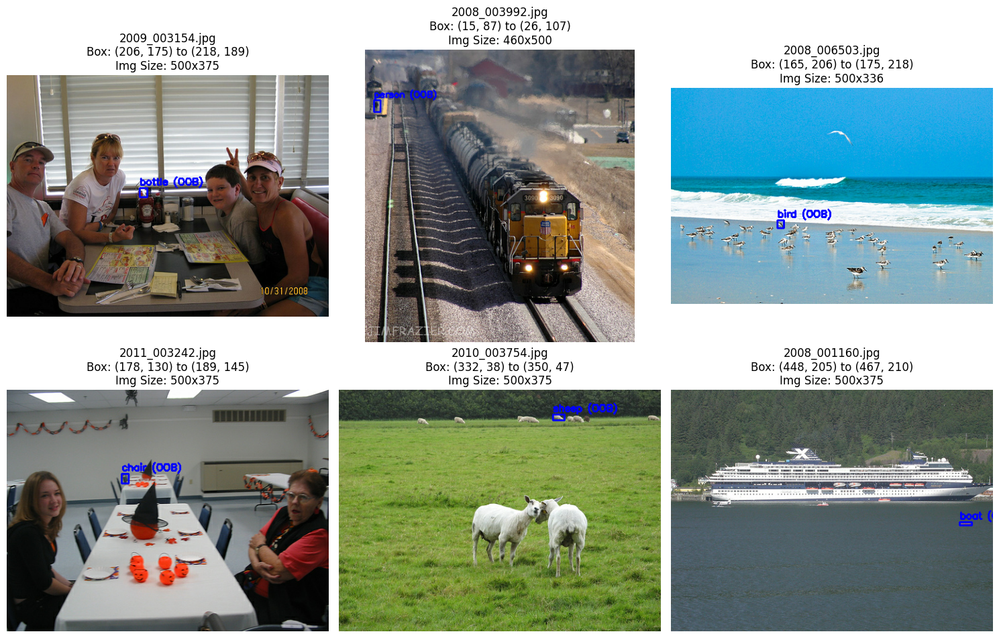

In [64]:
# Get a random sample of out-of-bounds annotations
num_samples = min(len(tiny_boxes), 6)
sampled_bounds = tiny_boxes.sample(num_samples, random_state=42)

# Create a dictionary of filename -> list of boxes for easy lookup
sample_filenames = set(sampled_bounds['filename'])

# Retrieve the raw images from our TFDS dataset splits
image_cache = {}
for split in ['train', 'validation']:
    if len(image_cache) >= len(sample_filenames):
        break
    for example in voc_ds[split]:
        filename = example['image/filename'].numpy().decode('utf-8')
        if filename in sample_filenames:
            image_cache[filename] = example['image'].numpy().copy()
        if len(image_cache) >= len(sample_filenames):
            break

# Plot the sampled images with their out-of-bounds bounding boxes
plt.figure(figsize=(15, 10))
for i, (idx, row) in enumerate(sampled_bounds.iterrows()):
    filename = row['filename']
    img = image_cache.get(filename)

    if img is not None:
        # Create a copy to draw on safely
        img_draw = img.copy()
        h, w, _ = img_draw.shape

        # Bounding box coordinates from the row
        xmin, ymin, xmax, ymax = int(row['xmin']), int(row['ymin']), int(row['xmax']), int(row['ymax'])

        # Draw the box boundaries clipping safely for visualization
        cv2.rectangle(img_draw, (xmin, ymin), (xmax, ymax), (0, 0, 255), 2)
        cv2.putText(img_draw, f"{row['class']} (OOB)", (max(xmin, 5), max(ymin - 5, 15)),
                    cv2.FONT_HERSHEY_SIMPLEX, 0.5, (0, 0, 255), 2)

        plt.subplot(2, 3, i + 1)
        plt.imshow(img_draw)
        plt.title(f"{filename}\nBox: ({xmin}, {ymin}) to ({xmax}, {ymax})\nImg Size: {w}x{h}")
        plt.axis('off')

plt.tight_layout()
plt.show()

### Class Encoding

In [51]:
# Map each class name to an integer id (alphabetical order)
classes = sorted(annotation_df['class'].unique())
class_to_id = {name: i for i, name in enumerate(classes)}
id_to_class = {i: name for name, i in class_to_id.items()}

# Add the numeric label as a new column
annotation_df['class_id'] = annotation_df['class'].map(class_to_id)

print("Number of classes:", len(classes))
print(class_to_id)

Number of classes: 20
{'aeroplane': 0, 'bicycle': 1, 'bird': 2, 'boat': 3, 'bottle': 4, 'bus': 5, 'car': 6, 'cat': 7, 'chair': 8, 'cow': 9, 'diningtable': 10, 'dog': 11, 'horse': 12, 'motorbike': 13, 'person': 14, 'pottedplant': 15, 'sheep': 16, 'sofa': 17, 'train': 18, 'tvmonitor': 19}


In [52]:
# Check: no missing ids, and each class has one id
print("Missing ids:", annotation_df['class_id'].isnull().sum())
display(annotation_df[['class', 'class_id']].drop_duplicates().sort_values('class_id'))

Missing ids: 0


,class,class_id
81,aeroplane,0
13,bicycle,1
122,bird,2
19,boat,3
30,bottle,4
39,bus,5
7,car,6
21,cat,7
36,chair,8
11,cow,9


# Feature Engineering

In [53]:
# Box width/height as a fraction of the image size
annotation_df['bbox_width_ratio'] = annotation_df['bbox_width'] / annotation_df['image_width']
annotation_df['bbox_height_ratio'] = annotation_df['bbox_height'] / annotation_df['image_height']

# Box center as a fraction of the image size (YOLO-style)
annotation_df['x_center'] = (annotation_df['xmin'] + annotation_df['xmax']) / 2 / annotation_df['image_width']
annotation_df['y_center'] = (annotation_df['ymin'] + annotation_df['ymax']) / 2 / annotation_df['image_height']

# Box shape: width / height
annotation_df['bbox_aspect_ratio'] = annotation_df['bbox_width'] / annotation_df['bbox_height']

In [54]:
# Object size category based on how much of the image it covers
annotation_df['size_category'] = pd.cut(
    annotation_df['bbox_area_ratio'],
    bins=[0, 0.05, 0.25, 1],
    labels=['small', 'medium', 'large']
)

# Number of objects in each image
annotation_df['objects_in_image'] = annotation_df.groupby('filename')['class'].transform('size')

In [55]:
display(annotation_df.head())
print(annotation_df['size_category'].value_counts())

,filename,class,difficult,truncated,image_width,image_height,xmin,ymin,xmax,ymax,...,bbox_area,bbox_area_ratio,bbox_width_ratio,bbox_height_ratio,class_id,x_center,y_center,bbox_aspect_ratio,size_category,objects_in_image
0,2008_004781.jpg,person,0,1,500,333,51.0,65.0,276.0,333.000000,...,60300.00000,0.362162,0.450,0.804805,14,0.327,0.597598,0.839552,large,2
1,2008_004781.jpg,tvmonitor,0,1,500,333,215.0,96.0,500.0,333.000000,...,67545.00000,0.405676,0.570,0.711712,19,0.715,0.644144,1.202532,large,2
2,2011_002053.jpg,train,0,1,500,375,1.0,113.0,486.0,342.000000,...,111065.00000,0.592347,0.970,0.610667,18,0.487,0.606667,2.117904,large,2
3,2011_002053.jpg,train,1,1,500,375,1.0,86.0,335.0,127.000008,...,13694.00293,0.073035,0.668,0.109333,18,0.336,0.284000,8.146340,medium,2
4,2011_003162.jpg,pottedplant,0,1,500,373,330.0,1.0,500.0,340.000000,...,57630.00000,0.309008,0.340,0.908847,15,0.830,0.457105,0.501475,large,3


size_category
small     12471
medium     9824
large      9266
Name: count, dtype: int64


# Data Splitting

In [56]:
from sklearn.model_selection import train_test_split

# Split by image (not by object), so one image never appears in two sets
image_list = annotation_df['filename'].unique()

# 70% train, 15% val, 15% test
train_imgs, temp_imgs = train_test_split(image_list, test_size=0.30, random_state=42)
val_imgs, test_imgs = train_test_split(temp_imgs, test_size=0.50, random_state=42)

# Each image brings all its objects with it
train_df = annotation_df[annotation_df['filename'].isin(train_imgs)]
val_df = annotation_df[annotation_df['filename'].isin(val_imgs)]
test_df = annotation_df[annotation_df['filename'].isin(test_imgs)]

In [57]:
print("Images -> train:", len(train_imgs), "| val:", len(val_imgs), "| test:", len(test_imgs))
print("Objects -> train:", len(train_df), "| val:", len(val_df), "| test:", len(test_df))

# No image should be in more than one set
print("Overlap train/val:", len(set(train_imgs) & set(val_imgs)))
print("Overlap train/test:", len(set(train_imgs) & set(test_imgs)))
print("Overlap val/test:", len(set(val_imgs) & set(test_imgs)))

Images -> train: 8078 | val: 1731 | test: 1731
Objects -> train: 22155 | val: 4592 | test: 4814
Overlap train/val: 0
Overlap train/test: 0
Overlap val/test: 0


In [58]:
# Class share (%) in each split, should be similar
dist = pd.DataFrame({
    'train': train_df['class'].value_counts(normalize=True) * 100,
    'val': val_df['class'].value_counts(normalize=True) * 100,
    'test': test_df['class'].value_counts(normalize=True) * 100,
}).round(2)

display(dist)

,train,val,test
class,,,
aeroplane,3.08,2.77,2.99
bicycle,2.45,3.05,2.24
bird,3.81,3.77,4.26
boat,2.98,3.64,3.57
bottle,4.83,3.55,5.17
bus,1.93,1.92,2.53
car,7.31,8.25,7.60
cat,3.84,3.42,4.57
chair,9.58,8.34,8.33


In [ ]:
import json
from google.colab import drive
drive.mount('/content/drive')

SAVE_DIR = '/content/drive/MyDrive/voc_project'
os.makedirs(SAVE_DIR, exist_ok=True)

# Optional: drop difficult objects from the training set only
# train_df = train_df[train_df['difficult'] == 0]

# Save the tables once, so you don't redo the preprocessing
train_df.to_csv(f'{SAVE_DIR}/train.csv', index=False)
val_df.to_csv(f'{SAVE_DIR}/val.csv', index=False)
test_df.to_csv(f'{SAVE_DIR}/test.csv', index=False)

# Save class mapping for the YOLO notebook
with open(f'{SAVE_DIR}/class_to_id.json', 'w') as f:
    json.dump(class_to_id, f)

print("Saved:", os.listdir(SAVE_DIR))

Saved CSV splits successfully to local environment!
